Libraries imported successfully!
Shape: (1303, 12)

First 5 rows:
  Company      Product   TypeName  Inches                    ScreenResolution                         Cpu   Ram               Memory                           Gpu  OpSys  Weight  Price_euros
0   Apple  MacBook Pro  Ultrabook    13.3  IPS Panel Retina Display 2560x1600        Intel Core i5 2.3GHz   8GB            128GB SSD  Intel Iris Plus Graphics 640  macOS  1.37kg      1339.69
1   Apple  Macbook Air  Ultrabook    13.3                            1440x900        Intel Core i5 1.8GHz   8GB  128GB Flash Storage        Intel HD Graphics 6000  macOS  1.34kg       898.94
2      HP       250 G6   Notebook    15.6                   Full HD 1920x1080  Intel Core i5 7200U 2.5GHz   8GB            256GB SSD         Intel HD Graphics 620  No OS  1.86kg       575.00
3   Apple  MacBook Pro  Ultrabook    15.4  IPS Panel Retina Display 2880x1800        Intel Core i7 2.7GHz  16GB            512GB SSD            AMD Radeon Pro 455  macOS 

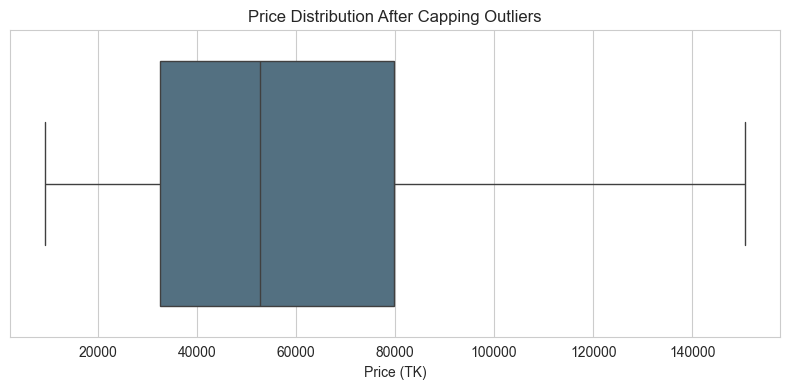

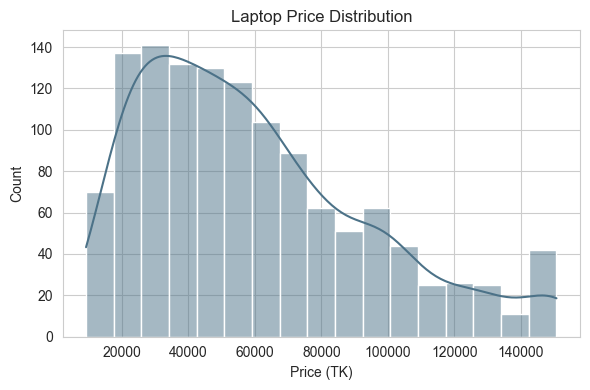

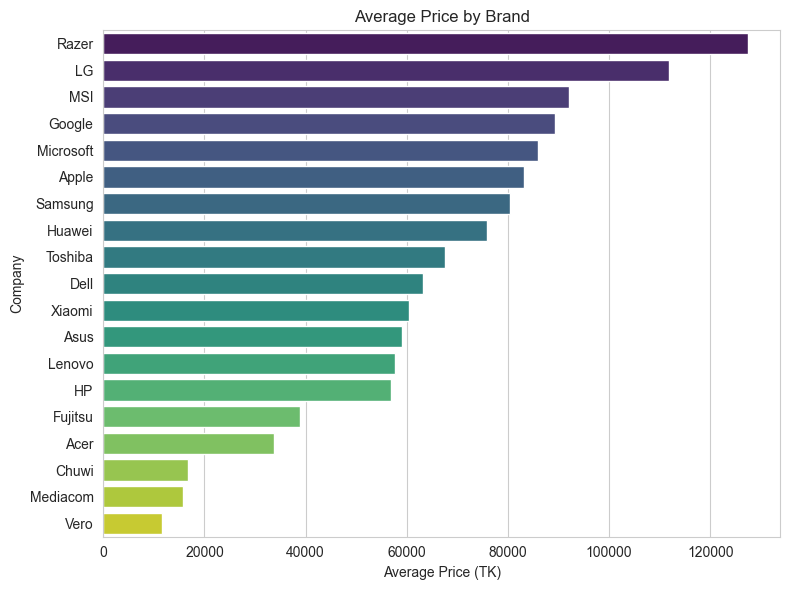

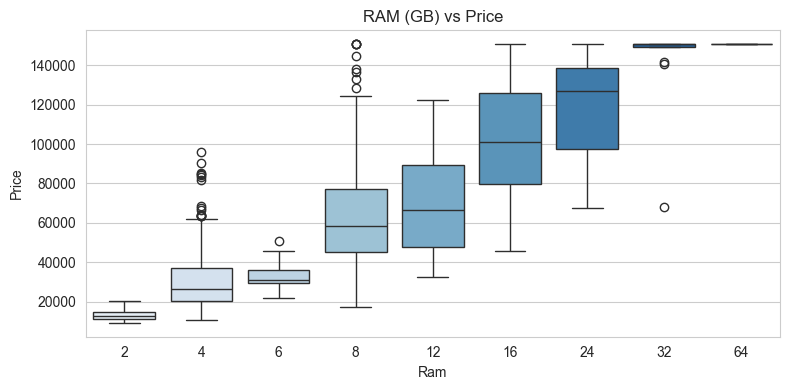

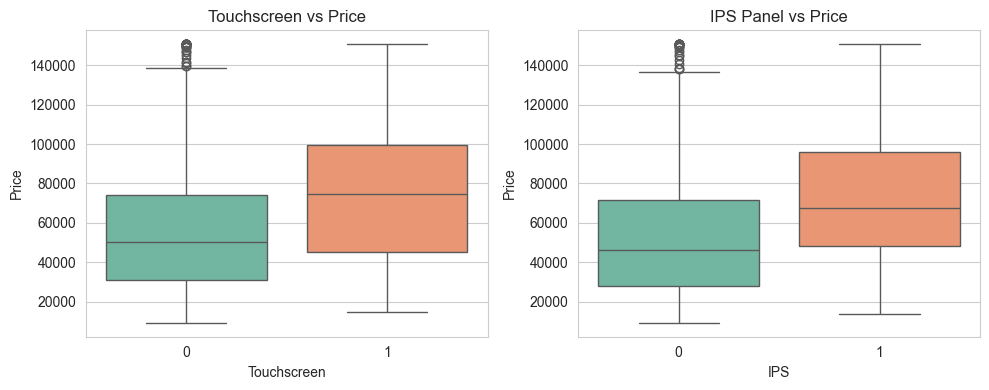

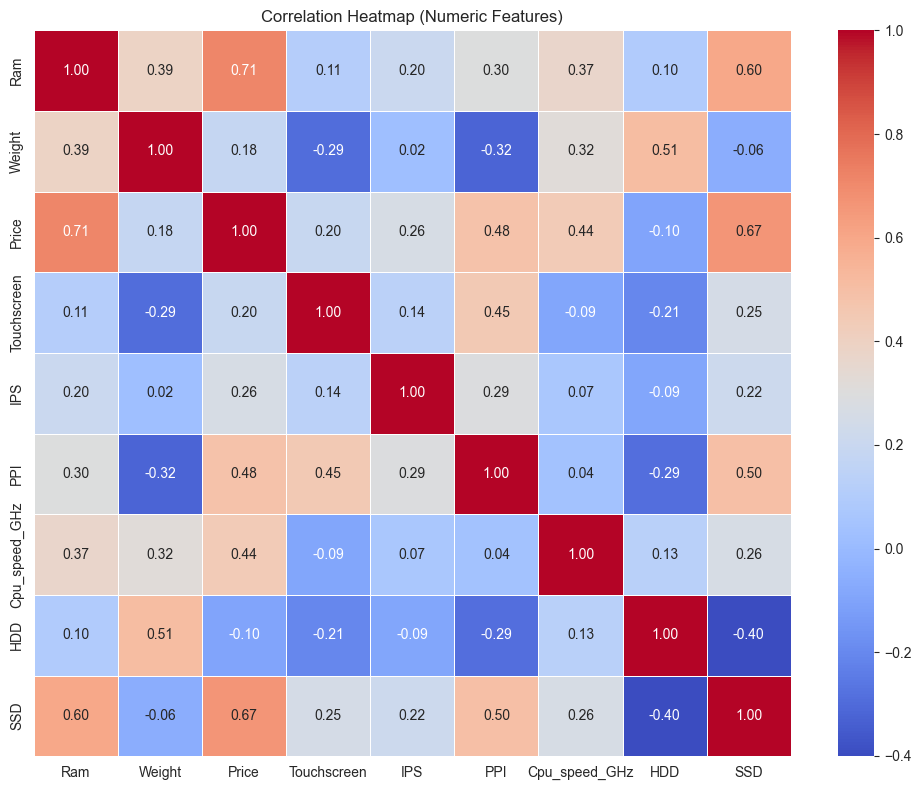


Train size: (1019, 13), Test size: (255, 13)

Model Evaluation Comparison Table:
               Model        R2           MAE          RMSE
1      Random Forest  0.822778   9478.276668  14497.911089
2  Gradient Boosting  0.808382   9486.766858  15075.259456
3      Decision Tree  0.771240  11181.260272  16471.640865
4  Linear Regression  0.352066  13622.032944  27721.184514
5   Lasso Regression  0.313222  13634.853118  28540.052616
6   Ridge Regression  0.260696  13922.306852  29611.344983


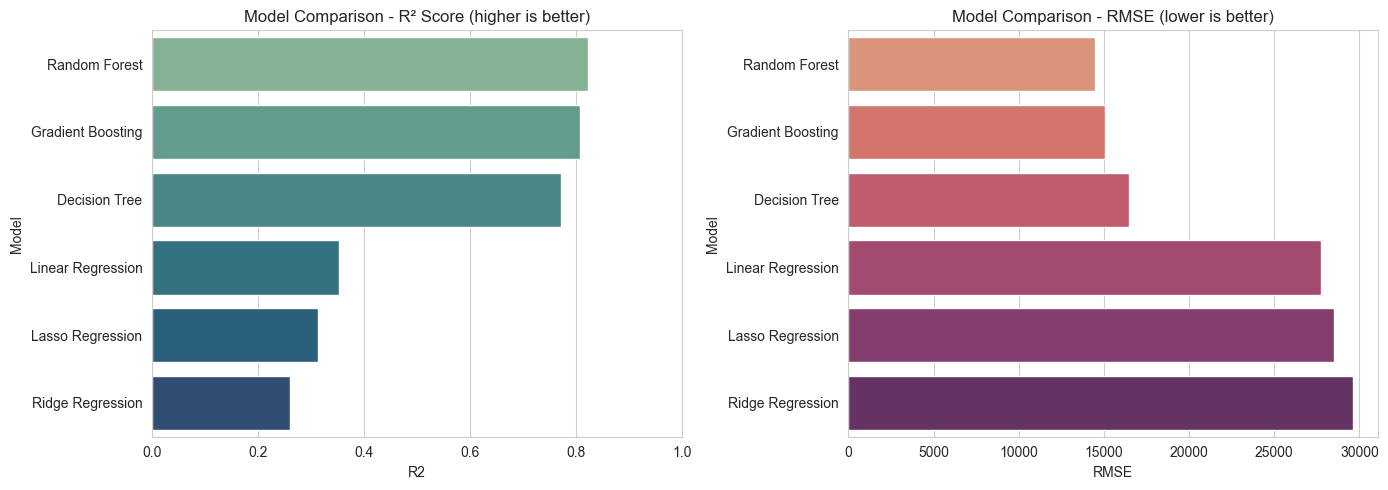

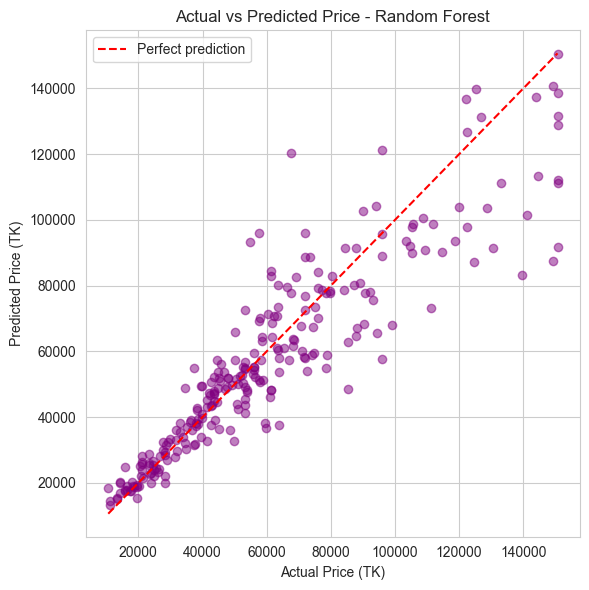

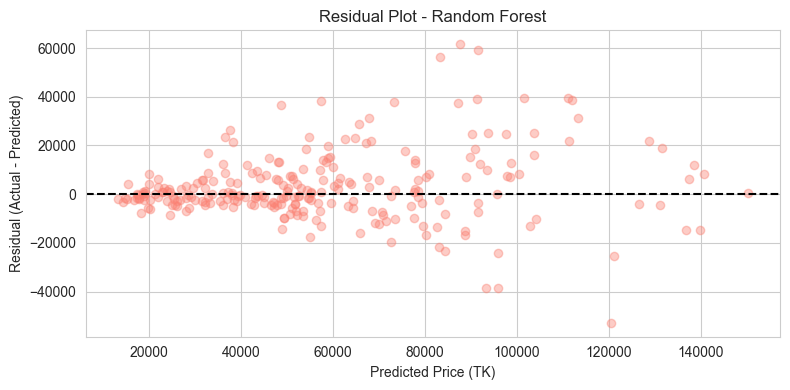

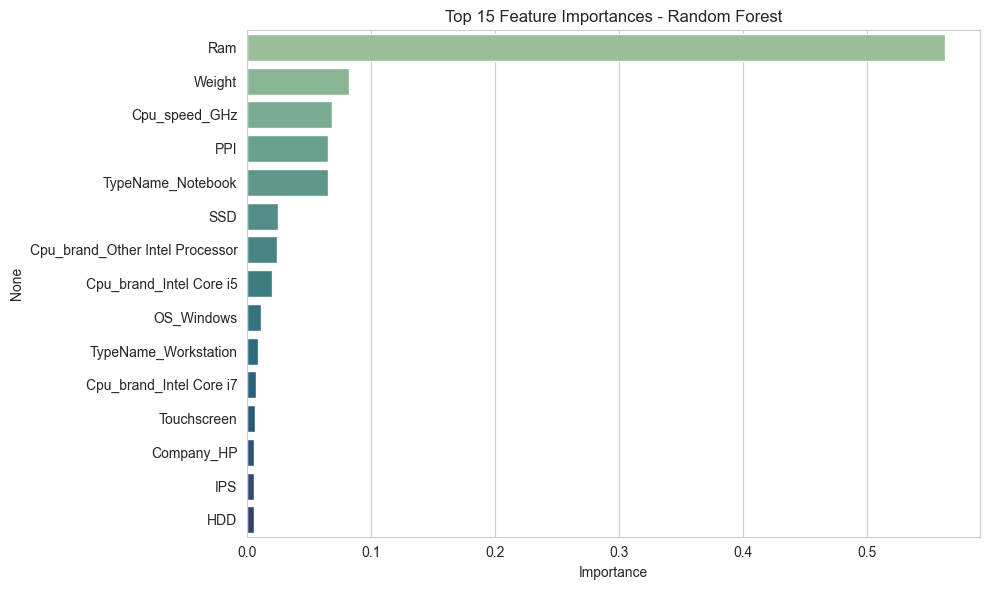


Execution completed successfully!


In [ ]:
# ==========================================
# 1. IMPORT LIBRARIES & SETUP
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100

print("Libraries imported successfully!")

# ==========================================
# 2. LOAD DATASET & INITIAL INSPECTION
# ==========================================

df = pd.read_csv('laptop_price.csv', encoding='latin-1')

# Drop unnamed index columns if any
df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")], inplace=True)
if 'laptop_ID' in df.columns:
    df.drop(columns=['laptop_ID'], inplace=True)

print("Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head().to_string())
print("\nDataFrame Info:")
df.info()

# ==========================================
# 3. DATA CLEANING & PREPROCESSING
# ==========================================
# Remove duplicates
print("\nDuplicate rows before removal:", df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print("Shape after removing duplicates:", df.shape)

# Check missing values
print("\nMissing values per column:\n", df.isnull().sum())

# Correct Data Types: Ram and Weight
df['Ram'] = df['Ram'].str.replace('GB', '', regex=False).astype(int)
df['Weight'] = df['Weight'].str.replace('kg', '', regex=False).astype(float)

# Convert Price from Euros to BDT (TK) using the exact conversion factor (53.28)
df['Price'] = df['Price_euros'] * 53.28
df.drop(columns=['Price_euros'], inplace=True)

# Outlier Treatment (IQR Method & Winsorization)
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"\nIQR bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
outliers_count = df[(df['Price'] < lower_bound) | (df['Price'] > upper_bound)].shape[0]
print("Outlier rows flagged:", outliers_count)

# Cap outliers
df['Price'] = df['Price'].clip(lower=lower_bound, upper=upper_bound)

# ==========================================
# 4. FEATURE ENGINEERING
# ==========================================
# Screen features: Touchscreen, IPS, PPI
df['Touchscreen'] = df['ScreenResolution'].apply(lambda x: 1 if "Touchscreen" in x else 0)
df['IPS'] = df['ScreenResolution'].apply(lambda x: 1 if "IPS" in x else 0)

def extract_res(s):
    m = re.search(r"(\d+)x(\d+)", str(s))
    return (int(m.group(1)), int(m.group(2))) if m else (np.nan, np.nan)

res = df["ScreenResolution"].apply(extract_res)
df["X_res"] = res.apply(lambda t: t[0])
df["Y_res"] = res.apply(lambda t: t[1])
df["PPI"] = (((df["X_res"] ** 2) + (df["Y_res"] ** 2)) ** 0.5 / df["Inches"]).astype(float)

# CPU brand bucket and clock speed
def cpu_bucket(name):
    name = str(name).strip()
    if "Intel Core i7" in name:
        return "Intel Core i7"
    elif "Intel Core i5" in name:
        return "Intel Core i5"
    elif "Intel Core i3" in name:
        return "Intel Core i3"
    elif "AMD" in name:
        return "AMD Processor"
    else:
        return "Other Intel Processor"

df["Cpu_brand"] = df["Cpu"].apply(cpu_bucket)
df["Cpu_speed_GHz"] = df["Cpu"].str.extract(r"(\d+\.?\d*)GHz").astype(float)

# Memory parsing
def parse_memory(mem):
    mem = (str(mem).replace("1.0TB", "1000GB").replace("2.0TB", "2000GB")
           .replace("1TB", "1000GB").replace("2TB", "2000GB"))
    hdd, ssd, hybrid, flash = 0, 0, 0, 0
    for p in mem.split("+"):
        p = p.strip()
        num = re.search(r"(\d+)GB", p)
        val = int(num.group(1)) if num else 0
        if "HDD" in p:
            hdd += val
        elif "SSD" in p:
            ssd += val
        elif "Hybrid" in p:
            hybrid += val
        elif "Flash" in p:
            flash += val
    return pd.Series([hdd, ssd, hybrid, flash])

df[["HDD", "SSD", "Hybrid", "Flash_Storage"]] = df["Memory"].apply(parse_memory)

# GPU brand and OS normalization
df["Gpu_brand"] = df["Gpu"].apply(lambda x: str(x).split()[0])
df = df[df["Gpu_brand"] != "ARM"] # drop single-row rare category noise

def os_bucket(x):
    x = str(x)
    if "Windows" in x:
        return "Windows"
    elif x in ("macOS", "Mac OS X"):
        return "Mac"
    elif "Linux" in x:
        return "Linux/Other"
    else:
        return "No OS/Other"

df["OS"] = df["OpSys"].apply(os_bucket)

# Drop redundant raw columns
df.drop(columns=["ScreenResolution", "Cpu", "Memory", "Gpu", "OpSys", "X_res", "Y_res", "Inches", "Hybrid", "Flash_Storage", "Product"], inplace=True)
print("\nFeature engineering complete. Final shape:", df.shape)

# ==========================================
# 5. EXPLORATORY DATA ANALYSIS & VISUALIZATIONS 
# ==========================================
# Figure 2: Price Distribution After Capping Outliers (Boxplot)
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Price'], color="#4C7288")
plt.title("Price Distribution After Capping Outliers")
plt.xlabel("Price (TK)")
plt.tight_layout()
plt.show()

# Figure 3: Laptop Price Distribution (Histogram + KDE)
plt.figure(figsize=(6, 4))
sns.histplot(df['Price'], kde=True, color="#4C7288")
plt.title("Laptop Price Distribution")
plt.xlabel("Price (TK)")
plt.tight_layout()
plt.show()

# Figure 4: Average Price by Brand
plt.figure(figsize=(8, 6))
brand_price = df.groupby("Company")["Price"].mean().sort_values(ascending=False)
sns.barplot(x=brand_price.values, y=brand_price.index, palette="viridis")
plt.title("Average Price by Brand")
plt.xlabel("Average Price (TK)")
plt.tight_layout()
plt.show()

# Figure 5: RAM vs Price
plt.figure(figsize=(8, 4))
sns.boxplot(x="Ram", y="Price", data=df, palette="Blues")
plt.title("RAM (GB) vs Price")
plt.tight_layout()
plt.show()

# Figure 6: Touchscreen & IPS Panel Impact
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(x="Touchscreen", y="Price", data=df, ax=ax[0], palette="Set2")
ax[0].set_title("Touchscreen vs Price")
sns.boxplot(x="IPS", y="Price", data=df, ax=ax[1], palette="Set2")
ax[1].set_title("IPS Panel vs Price")
plt.tight_layout()
plt.show()

# Figure 7: Correlation Heatmap (Numeric Features)
plt.figure(figsize=(10, 8))
num_cols = df.select_dtypes(include=[np.number]).columns
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap (Numeric Features)")
plt.tight_layout()
plt.show()

# ==========================================
# 6. MACHINE LEARNING MODEL DEVELOPMENT 
# ==========================================
X = df.drop(columns=['Price'])
y_log = np.log(df['Price']) # Target transformation to log scale

X_train, X_test, y_train, y_test = train_test_split(X, y_log, test_size=0.20, random_state=42)
print(f"\nTrain size: {X_train.shape}, Test size: {X_test.shape}")

cat_features = ["Company", "TypeName", "Cpu_brand", "Gpu_brand", "OS"]
num_features = [c for c in X.columns if c not in cat_features]

preprocess = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_features),
        ('num', StandardScaler(), num_features)
    ]
)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10),
    "Lasso Regression": Lasso(alpha=0.001),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=15, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
}

results = []
predictions = {}

for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    
    # Back-transform predictions to TK using exp()
    pred = np.exp(pipe.predict(X_test))
    actual = np.exp(y_test)
    
    r2 = r2_score(actual, pred)
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    
    results.append({"Model": name, "R2": r2, "MAE": mae, "RMSE": rmse})
    predictions[name] = (actual, pred, pipe)

results_df = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
results_df.index += 1
print("\nModel Evaluation Comparison Table:")
print(results_df.to_string())

# ==========================================
# 7. MODEL COMPARISON VISUALIZATIONS 
# ==========================================
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x="R2", y="Model", data=results_df, ax=ax[0], palette="crest")
ax[0].set_title("Model Comparison - R² Score (higher is better)")
ax[0].set_xlim(0, 1.0)

sns.barplot(x="RMSE", y="Model", data=results_df, ax=ax[1], palette="flare")
ax[1].set_title("Model Comparison - RMSE (lower is better)")
plt.tight_layout()
plt.show()

# ==========================================
# 8. CHAMPION MODEL (RANDOM FOREST) & FEATURE IMPORTANCE 
# ==========================================
best_name = "Random Forest"
actual, pred, best_pipe = predictions[best_name]

# Figure 10: Actual vs Predicted Price
plt.figure(figsize=(6, 6))
plt.scatter(actual, pred, alpha=0.5, color='purple')
plt.plot([actual.min(), actual.max()], [actual.min(), actual.max()], 'r--', label="Perfect prediction")
plt.title(f"Actual vs Predicted Price - {best_name}")
plt.xlabel("Actual Price (TK)")
plt.ylabel("Predicted Price (TK)")
plt.legend()
plt.tight_layout()
plt.show()

# Figure 11: Residual Plot
plt.figure(figsize=(8, 4))
residuals = actual - pred
plt.scatter(pred, residuals, alpha=0.4, color='salmon')
plt.axhline(y=0, color='black', linestyle='--')
plt.title(f"Residual Plot - {best_name}")
plt.xlabel("Predicted Price (TK)")
plt.ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

# Figure 12: Top 15 Feature Importances
ohe_cols = list(best_pipe.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(cat_features))
importances = best_pipe.named_steps['model'].feature_importances_
fi = pd.Series(importances, index=ohe_cols + num_features).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=fi.values, y=fi.index, palette="crest")
plt.title(f"Top 15 Feature Importances - {best_name}")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("\nExecution completed successfully!")